In Chapter 17, we saw that a Recurrent Neural Network (RNN) trained by backpropagation through time (BPTT) has trouble learning long-range dependencies. The gradient that links an error at time $T$ to the state at an earlier time $t$ is a product of $T - t$ Jacobian matrices, so it vanishes or explodes exponentially with the lag. The Echo State Network (ESN) avoided the problem by not training the recurrent weights at all.

The **Long Short-Term Memory (LSTM)** network, introduced by Hochreiter and Schmidhuber in 1997, takes the opposite route. It keeps training every weight by BPTT, but it changes the recurrent unit so that information, and the gradient, can travel over many steps. The unit carries a second state vector, the **cell state**, which changes only through element-wise multiplications and additions, and three learned **gates** decide what to erase from it, what to write to it and what to read from it. LSTMs are behind many of the successes of RNNs in speech recognition, machine translation and language modeling, and they are a standard tool for time series forecasting, anomaly detection and other sequence tasks.

In this chapter, we go through the LSTM unit one gate at a time, see why its gradient can survive over long lags, review the main variants, including the Gated Recurrent Unit (GRU), and forecast the Rome electricity load of Chapters 16 and 17 with an LSTM that we write and train ourselves.

# Learning objectives

By the end of this lecture, you should be able to

1. explain why a plain RNN fails to learn long-term dependencies, and how the cell state of an LSTM addresses the problem;
2. write the equations of the forget gate, the input gate, the candidate cell state, the cell-state update, the output gate and the hidden state, and explain the role of each;
3. explain why the gradient along the cell state does not have to vanish, and why the forget-gate bias is initialized to a positive value;
4. describe the main variants of the LSTM: peephole connections, coupled forget and input gates, and the GRU;
5. train an LSTM on a time series by backpropagation through time, with a washout, gradient clipping and the Adam optimizer, and check hand-written gradients against finite differences;
6. forecast a time series with an LSTM, compare it with the benchmarks of Chapters 16 and 17, and look inside the model at what its gates do.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `tanh`, `exp`, `random.default_rng`, matrix products -- the LSTM itself |
| `pandas` | `read_csv`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `imshow` -- the heat map of the gates |
| `time` | `perf_counter` -- timing the fits |

We write the LSTM ourselves in NumPy, as we did for the reservoir in Chapter 17: the forward pass, the backward pass and the optimizer take about 100 lines. Deep-learning libraries such as PyTorch and Keras provide ready-made LSTM layers and compute the gradients automatically. At the end of the chapter, we show the same model in PyTorch for reference.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4) and the MSE (Chapter 6).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)

---

# Problem of long-term dependencies in RNN

RNNs are designed to handle sequential data by using a hidden state $\mathbf{h}(t)$ that stores information from previous steps. However, they struggle to learn long-term dependencies. This happens due to:

- **Vanishing Gradient**: When training a model over time, the gradients which help the model learn can shrink as they pass through many steps. This makes it hard for the model to learn long-term patterns since earlier information becomes almost irrelevant.
- **Exploding Gradient**: Sometimes gradients can grow too large causing instability. This makes it difficult for the model to learn properly as the updates to the model become erratic and unpredictable.

---

# The LSTM unit

Long Short-Term Memory (LSTM) is an improved version of the RNN designed to capture long-term dependencies in sequential data. It uses a memory cell to store information over time, solving the limitations of traditional RNNs.

- **Handles Long Term Dependencies**: Remembers information for longer sequences
- **Memory Cell**: Stores and updates important information over time
- **Better than RNN**: Overcomes short term memory limitations

## The core idea: the cell state

The repeating unit of an RNN has a single layer: the new state is one $\tanh$ of the input and the previous state. In the notation of this chapter, $\mathbf{h}(t) = \tanh\big(\mathbf{W}\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}\big)$, where $[\mathbf{h}(t-1), x(t)]$ is the concatenation of the previous state and the current input. The repeating unit of an LSTM has **four** layers, which interact in a particular way, and it passes **two** vectors from one step to the next: the hidden state $\mathbf{h}(t)$ and the **cell state** $\mathbf{c}(t)$, both of size $N_h$.

<img src="media/LSTM/lstm_cell.png" style="width: 75%; display: block; margin: auto;">

In the diagram, each line carries a whole vector. The yellow boxes are learned layers, a linear map followed by an activation function, and the pink shapes are element-wise operations. Lines that merge are concatenated, and lines that fork are copied.

The key is the blue line at the top, the cell state. It runs straight through the unit with only two element-wise operations on it, a multiplication and an addition. Information can ride along it unchanged from one step to the next, like goods on a conveyor belt, and the unit changes it only by controlled amounts. The control is done by **gates**. A gate is a sigmoid layer followed by an element-wise multiplication. The sigmoid outputs a number between 0 and 1 for each component: 0 means "let nothing through", and 1 means "let everything through". An LSTM unit has three gates.

All four layers read the same input, the vector $[\mathbf{h}(t-1), x(t)]$ of size $N_h + d$, where $d$ is the number of input variables ($d = 1$ for a univariate series).

## Step by step

### The forget gate $\mathbf{f}(t)$

The **forget gate** $\mathbf{f}(t)$ decides which information should be kept or removed from the cell state. It use the current input $x(t)$ and the previous hidden state $\mathbf{h}(t-1)$ then applies a sigmoid activation function to generate values between 0 and 1 for each component of $\mathbf{c}(t-1)$. 

<img src="media/LSTM/forget_gate.jpg" style="width: 12%; display: block; margin: auto;">

$$\mathbf{f}(t) = \sigma\big(\mathbf{W}_f\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_f\big),$$

where $\sigma(a) = 1/(1 + e^{-a})$ is the logistic sigmoid activation function, $\mathbf{W}_f$ is an $N_h \times (N_h + d)$ weight matrix associated with the forget gate, and $\mathbf{b}_f$ is a bias vector with the forget gate. 

- Values close to 0 remove information
- Values close to 1 retain information
- Helps discard unnecessary past information
- Controls memory retention in the LSTM

### The input gate and the candidate

The second step decides what new information to store, in two parts. The addition of useful information to the cell state is done by the input gate.

- First the information is regulated using the sigmoid function and filter the values to be remembered similar to the forget gate using inputs $\mathbf{h}(t-1)$ and $x(t)$.
- Then, a $\tanh$ layer proposes a vector of **candidate values** $\tilde{\mathbf{c}}(t)$, between $-1$ and $1$, and a sigmoid layer, the **input gate** $\mathbf{i}(t)$, decides which components of the candidate to let in, and how much.

$$\mathbf{i}(t) = \sigma\big(\mathbf{W}_i\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_i\big), \qquad \tilde{\mathbf{c}}(t) = \tanh\big(\mathbf{W}_c\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_c\big).$$

<img src="media/LSTM/input_gate.jpg" style="width: 12%; display: block; margin: auto;">

### The cell-state update

Next, the old cell state is turned into the new one. We multiply the previous state $\mathbf{c}(t-1)$ by the forget gate $\mathbf{f}(t)$, which erases what we decided to forget, and add the candidate, scaled by the input gate,

$$\mathbf{c}(t) = \mathbf{f}(t) \odot \mathbf{c}(t-1) + \mathbf{i}(t) \odot \tilde{\mathbf{c}}(t),$$

where $\odot$ is the element-wise product. This is the only place where the cell state changes, and the new information is **added**, not substituted.

### The output gate and the hidden state

Finally, the unit decides what to output. The output is a filtered version of the cell state: the cell state goes through a $\tanh$, which puts its values between $-1$ and $1$, and is multiplied by the **output gate** $\mathbf{o}(t)$, a sigmoid layer that decides which components to reveal.

<img src="media/LSTM/output_gate.jpg" style="width: 12%; display: block; margin: auto;">

$$\mathbf{o}(t) = \sigma\big(\mathbf{W}_o\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_o\big), \qquad \mathbf{h}(t) = \mathbf{o}(t) \odot \tanh\big(\mathbf{c}(t)\big).$$

The hidden state $\mathbf{h}(t)$ goes to the next step and to the output layer. For forecasting, the output layer is linear, $y(t) = \mathbf{w}_y^\top \mathbf{h}(t) + b_y$, like the readout of the ESN. (Here, $\mathbf{W}_o$ belongs to the output gate, so we call the readout weights $\mathbf{w}_y$.)

## The equations together

$$
\begin{aligned}
\mathbf{f}(t) &= \sigma\big(\mathbf{W}_f\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_f\big) && \text{forget gate}\\
\mathbf{i}(t) &= \sigma\big(\mathbf{W}_i\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_i\big) && \text{input gate}\\
\tilde{\mathbf{c}}(t) &= \tanh\big(\mathbf{W}_c\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_c\big) && \text{candidate}\\
\mathbf{c}(t) &= \mathbf{f}(t) \odot \mathbf{c}(t-1) + \mathbf{i}(t) \odot \tilde{\mathbf{c}}(t) && \text{cell state}\\
\mathbf{o}(t) &= \sigma\big(\mathbf{W}_o\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_o\big) && \text{output gate}\\
\mathbf{h}(t) &= \mathbf{o}(t) \odot \tanh\big(\mathbf{c}(t)\big) && \text{hidden state}
\end{aligned}
$$

The states start from $\mathbf{h}(0) = \mathbf{c}(0) = \mathbf{0}$. An RNN overwrites its whole state at every step, while an LSTM decides, component by component, how much of its memory to keep and how much new information to add.

**Number of parameters.** Each of the four layers has an $N_h \times (N_h + d)$ weight matrix and $N_h$ biases, so an LSTM layer has $4 N_h (N_h + d + 1)$ parameters, four times as many as an RNN layer of the same size. In the `LSTM` class, the four weight matrices are stored transposed and side by side in one array `W` of shape $(N_h + d) \times 4N_h$, so that a single matrix product computes all four layers. Its column blocks belong to $\mathbf{f}$, $\mathbf{i}$, $\tilde{\mathbf{c}}$ and $\mathbf{o}$, in that order. Its first $N_h$ rows multiply $\mathbf{h}(t-1)$, and its last $d$ rows multiply $x(t)$. The input part does not depend on the state, so `forward` computes it for all steps at once before the loop.

**Three operations of an LSTM unit**: 

- **write** (input gate open),
- **hold** (forget gate open, input gate closed)
- **erase** (forget gate closed).

In a trained LSTM, nobody sets the weights by hand: the network learns from the data when to open and close each gate.

New in this chapter: the logistic function `sigmoid`, and the `LSTM` class. The class computes the forward pass of an LSTM layer with a linear output, computes the gradients of a loss by backpropagation through time, and fits the weights with the Adam optimizer. We explain each piece in the sections below.

In [3]:
def sigmoid(a):
    "Logistic function 1 / (1 + exp(-a)), with values between 0 and 1."
    return 1.0 / (1.0 + np.exp(-a))


class LSTM:
    """One LSTM layer with a linear output y(t) = w_y . h(t) + b_y at every step.

    Arrays are time-major: an input X has shape (T, B, n_inputs), for T steps of B sequences.
    The weights of the four layers are stored side by side in W, of shape
    (n_units + n_inputs, 4 n_units). W acts on the concatenation [h(t-1), x(t)], and its
    column blocks belong to f, i, c~ and o, in that order.
    """

    def __init__(self, n_inputs=1, n_units=16, forget_bias=1.0, seed=0):
        rng = np.random.default_rng(seed)
        N, k = n_units, 1 / np.sqrt(n_units)
        self.n_units = N
        self.params = {"W": rng.uniform(-k, k, (N + n_inputs, 4 * N)),
                       "b": np.zeros(4 * N),
                       "w_y": rng.uniform(-k, k, N),
                       "b_y": np.zeros(1)}
        self.params["b"][:N] = forget_bias              # the forget gates start mostly open

    def forward(self, X):
        "Outputs y(t) of every step, shape (T, B), and the values needed by `backward`."
        W, b, N = self.params["W"], self.params["b"], self.n_units
        T, B, _ = X.shape
        Z = X @ W[N:] + b                               # input part of the four layers, all steps at once
        h, c = np.zeros((B, N)), np.zeros((B, N))       # h(0) = c(0) = 0
        H, C, F, I, G, O = [h], [c], [], [], [], []
        for t in range(T):
            z = Z[t] + h @ W[:N]                        # W [h(t-1), x(t)] + b, for the four layers
            f = sigmoid(z[:, :N])                       # forget gate
            i = sigmoid(z[:, N:2 * N])                  # input gate
            g = np.tanh(z[:, 2 * N:3 * N])              # candidate cell state c~(t)
            o = sigmoid(z[:, 3 * N:])                   # output gate
            c = f * c + i * g                           # new cell state
            h = o * np.tanh(c)                          # new hidden state
            for store, value in zip((H, C, F, I, G, O), (h, c, f, i, g, o)):
                store.append(value)
        cache = {name: np.array(v) for name, v in zip("HCFIGO", (H, C, F, I, G, O))}
        cache["X"] = X
        Y = cache["H"][1:] @ self.params["w_y"] + self.params["b_y"][0]
        return Y, cache

    def backward(self, dY, cache):
        """Backpropagation through time, given dLoss/dy(t) of shape (T, B).

        Returns the gradients of the parameters. The gradients with respect to the initial
        states h(0) and c(0) are kept in self.dh0 and self.dc0.
        """
        W, N = self.params["W"], self.n_units
        X, H, C = cache["X"], cache["H"], cache["C"]
        T, B, n_inputs = X.shape
        dZ = np.empty((T, B, 4 * N))
        dh, dc = np.zeros((B, N)), np.zeros((B, N))
        dH = dY[..., None] * self.params["w_y"]         # from the outputs y(t) to h(t)
        for t in range(T - 1, -1, -1):
            f, i, g, o = cache["F"][t], cache["I"][t], cache["G"][t], cache["O"][t]
            tanh_c = np.tanh(C[t + 1])
            dh = dh + dH[t]                             # dLoss / dh(t)
            dc = dc + dh * o * (1 - tanh_c ** 2)        # dLoss / dc(t)
            dZ[t, :, :N] = dc * C[t] * f * (1 - f)              # forget gate
            dZ[t, :, N:2 * N] = dc * g * i * (1 - i)            # input gate
            dZ[t, :, 2 * N:3 * N] = dc * i * (1 - g ** 2)       # candidate
            dZ[t, :, 3 * N:] = dh * tanh_c * o * (1 - o)        # output gate
            dh = dZ[t] @ W[:N].T                        # to h(t-1), through the four layers
            dc = dc * f                                 # to c(t-1), along the cell state
        self.dh0, self.dc0 = dh, dc
        dZ = dZ.reshape(-1, 4 * N)
        return {"W": np.vstack([H[:-1].reshape(-1, N).T @ dZ, X.reshape(-1, n_inputs).T @ dZ]),
                "b": dZ.sum(axis=0),
                "w_y": H[1:].reshape(-1, N).T @ dY.ravel(),
                "b_y": np.array([dY.sum()])}

    def loss_and_grads(self, X, Y, mask):
        "MSE over the steps where mask is 1, and its gradients."
        Y_hat, cache = self.forward(X)
        err = (Y_hat - Y) * mask
        n = mask.sum()
        return np.sum(err ** 2) / n, self.backward(2 * err / n, cache)

    def fit(self, X, Y, mask, epochs=100, lr=0.01, clip=1.0, callback=None):
        """Full-batch Adam with gradient clipping. Returns the training loss of every epoch;
        callback(self), if given, is called after every epoch."""
        m = {k: np.zeros_like(p) for k, p in self.params.items()}
        v = {k: np.zeros_like(p) for k, p in self.params.items()}
        losses = []
        for step in range(1, epochs + 1):
            loss, grads = self.loss_and_grads(X, Y, mask)
            norm = np.sqrt(sum(np.sum(gr ** 2) for gr in grads.values()))
            if norm > clip:                             # gradient clipping
                grads = {k: gr * clip / norm for k, gr in grads.items()}
            for k, p in self.params.items():            # Adam update
                m[k] = 0.9 * m[k] + 0.1 * grads[k]
                v[k] = 0.999 * v[k] + 0.001 * grads[k] ** 2
                p -= lr * (m[k] / (1 - 0.9 ** step)) / (np.sqrt(v[k] / (1 - 0.999 ** step)) + 1e-8)
            losses.append(loss)
            if callback is not None:
                callback(self)
        return losses

## Why the gradient survives

An LSTM is trained like the RNN of Chapter 17: backpropagation through time unfolds it over the sequence and applies the chain rule backward, from the last step to the first. The method `backward` does exactly that, one step at a time, using the gates stored by `forward`. Its last line in the loop is the important one. The cell-state update $\mathbf{c}(t) = \mathbf{f}(t) \odot \mathbf{c}(t-1) + \mathbf{i}(t) \odot \tilde{\mathbf{c}}(t)$ gives

$$\frac{\partial \mathbf{c}(t)}{\partial \mathbf{c}(t-1)} = \mathrm{diag}\big(\mathbf{f}(t)\big)$$

along the cell state, so the gradient carried back from $\mathbf{c}(T)$ to $\mathbf{c}(t)$ along this path is multiplied by the product of the forget gates, $\prod_{s=t+1}^{T} \mathrm{diag}\big(\mathbf{f}(s)\big)$. Compare it with the RNN factor $\mathrm{diag}\big(1 - \mathbf{h}(s)^2\big)\,\mathbf{W}_h$: there is no weight matrix in it, and no derivative of a squashing function. When the forget gates are close to 1, the product stays close to 1, and the gradient travels back over many steps almost unchanged. The original LSTM of 1997 had no forget gate: its cell state was carried over with a fixed factor of exactly 1, a path its authors called the **constant error carousel**. Gers, Schmidhuber and Cummins (2000) added the forget gate, so that a cell can also reset its memory. The gradient also flows along other paths, through $\mathbf{h}(t-1)$ and the four layers, and those can vanish or explode like in an RNN. But one path that does not vanish is enough to connect distant steps.

The forget gates are learned and depend on the input, so the network itself decides how long to remember. At the start of training, though, a forget-gate bias of 0 gives $\mathbf{f}(t) \approx \sigma(0) = 0.5$, and the product halves at every step: the LSTM starts out as forgetful as an RNN. The forget-gate bias is therefore usually initialized to a positive value, often 1, as recommended by Jozefowicz, Zaremba and Sutskever (2015). Keras does it by default (`unit_forget_bias=True`), and our `LSTM` class has `forget_bias=1.0`.

We measure the effect with the backward pass of our class. For an LSTM with 50 units and random weights, we feed the first $T$ hours of the standardized Rome load, inject a gradient of 1 at the last output $y(T)$ only, and read `dc0`, the gradient of $y(T)$ with respect to the initial cell state $\mathbf{c}(0)$. Its norm tells how strongly the output at time $T$ can respond to, and therefore learn from, the memory at time 0. We repeat this for $T = 1, \dots, 100$ and for forget-gate biases $b_f = 0, 1, 2$ and $3$.

b_f = 0.0: mean forget gate 0.50,  |dy(T)/dc(0)| at T = 10, 50, 100: 1.1e-03, 6.0e-11, 5.8e-20
b_f = 1.0: mean forget gate 0.73,  |dy(T)/dc(0)| at T = 10, 50, 100: 2.6e-02, 1.6e-04, 3.6e-07
b_f = 2.0: mean forget gate 0.88,  |dy(T)/dc(0)| at T = 10, 50, 100: 1.3e-01, 3.1e-01, 1.0e+00
b_f = 3.0: mean forget gate 0.95,  |dy(T)/dc(0)| at T = 10, 50, 100: 2.4e-01, 8.4e-01, 6.2e-01


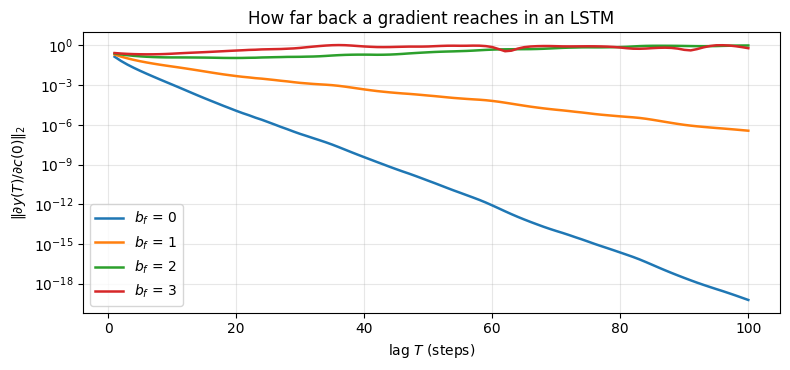

b_f = 2.0: mean forget gate 0.88,  |dy(T)/dc(0)| at T = 10, 50, 100: 1.3e-01, 3.1e-01, 1.0e+00


b_f = 3.0: mean forget gate 0.95,  |dy(T)/dc(0)| at T = 10, 50, 100: 2.4e-01, 8.4e-01, 6.2e-01


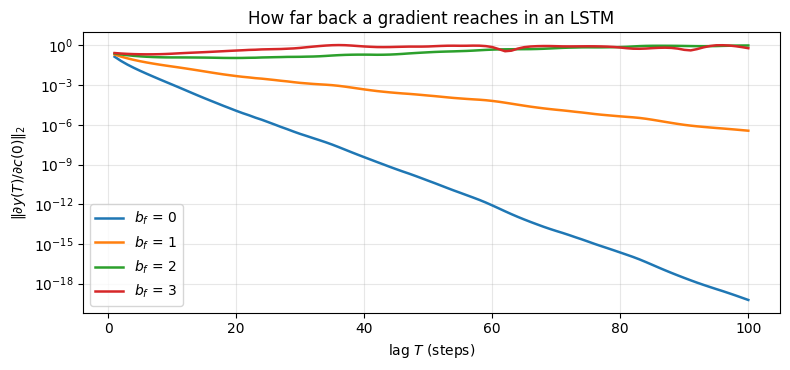

In [4]:
rome = pd.read_csv("data/elec_rome_hourly.csv", index_col="step")["load"]
time_series = rome.to_numpy()[:3000]
x_demo = (time_series[:100] - time_series.mean()) / time_series.std()

fig, ax = plt.subplots(figsize=(8, 3.8))
for b_f in [0.0, 1.0, 2.0, 3.0]:
    net = LSTM(n_inputs=1, n_units=50, forget_bias=b_f, seed=8990)
    norms = []
    for T in range(1, 101):
        _, cache = net.forward(x_demo[:T, None, None])
        dY = np.zeros((T, 1))
        dY[-1] = 1.0                                    # gradient of y(T) only
        net.backward(dY, cache)
        norms.append(np.linalg.norm(net.dc0))
    print(f"b_f = {b_f}: mean forget gate {cache['F'].mean():.2f},  "
          f"|dy(T)/dc(0)| at T = 10, 50, 100: {norms[9]:.1e}, {norms[49]:.1e}, {norms[99]:.1e}")
    ax.plot(np.arange(1, 101), norms, lw=1.8, label=f"$b_f$ = {b_f:g}")
ax.set(yscale="log", xlabel="lag $T$ (steps)", ylabel=r"$\| \partial y(T) / \partial c(0) \|_2$",
       title="How far back a gradient reaches in an LSTM")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- With $b_f = 0$, the forget gates sit around 0.50, and the sensitivity falls to $5.8 \times 10^{-20}$ after 100 steps. That is between the RNNs with $\rho = 0.5$ and $\rho = 0.9$ of Chapter 17 (about $10^{-37}$ and $10^{-15}$): with this initialization, the LSTM forgets like an RNN.
- With $b_f = 1$, the gates average 0.73, and the decay is much slower, but the sensitivity still drops to $3.6 \times 10^{-7}$ after 100 steps.
- With $b_f = 2$ and $b_f = 3$ (gates around 0.88 and 0.95), it does not decay at all: at $T = 100$, it is 1.0 and 0.62, larger than at $T = 10$. The output 100 steps later still responds to the initial memory.

These are the gates of an untrained network with random weights. Training changes the weights and the biases, and the network learns its own forget gates. But training starts from here, and the first gradient steps can only learn the dependencies that the gradient reaches. A positive forget-gate bias gives the long lags a chance.

## Checking the gradients

The method `backward` is about twenty lines of hand-written chain rule. A wrong sign or a wrong index would not stop the training, it would only make it worse, and we might never notice. Before training, we therefore compare the gradients with **finite differences**: for each parameter $\theta$,

$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon},$$

with a small $\varepsilon$, here $10^{-6}$. We use a small LSTM with $N_h = 4$ units and $d = 2$ inputs, 5 random sequences of 7 steps, and a random mask that keeps about half of the steps in the loss.

In [5]:
rng = np.random.default_rng(8990)
small = LSTM(n_inputs=2, n_units=4, seed=1)
X_chk, Y_chk = rng.normal(size=(7, 5, 2)), rng.normal(size=(7, 5))
mask_chk = (rng.random((7, 5)) < 0.5).astype(float)
_, grads = small.loss_and_grads(X_chk, Y_chk, mask_chk)

eps = 1e-6
for name, p in small.params.items():
    numeric = np.zeros_like(p)
    for idx in np.ndindex(p.shape):
        p_old = p[idx]
        p[idx] = p_old + eps
        loss_plus = small.loss_and_grads(X_chk, Y_chk, mask_chk)[0]
        p[idx] = p_old - eps
        loss_minus = small.loss_and_grads(X_chk, Y_chk, mask_chk)[0]
        p[idx] = p_old
        numeric[idx] = (loss_plus - loss_minus) / (2 * eps)
    rel_error = np.max(np.abs(numeric - grads[name])) / np.max(np.abs(numeric))
    print(f"{name:4s} {p.size:3d} parameters, max relative error {rel_error:.1e}")

W     96 parameters, max relative error 1.2e-09
b     16 parameters, max relative error 5.7e-10
w_y    4 parameters, max relative error 2.4e-10
b_y    1 parameters, max relative error 4.3e-11


For every parameter, the gradients of `backward` and the finite differences agree to a relative error of about $10^{-9}$, the precision we can expect from finite differences with $\varepsilon = 10^{-6}$. The backward pass is correct, and we can train with it.

---

# Variants of the LSTM

Almost every paper that uses LSTMs uses a slightly different version. The differences are minor, but a few are worth knowing.

## Peephole connections

Gers and Schmidhuber (2000) let the gate layers look at the cell state as well, through **peephole connections**,

$$
\begin{aligned}
\mathbf{f}(t) &= \sigma\big(\mathbf{W}_f\,[\mathbf{c}(t-1), \mathbf{h}(t-1), x(t)] + \mathbf{b}_f\big),\\
\mathbf{i}(t) &= \sigma\big(\mathbf{W}_i\,[\mathbf{c}(t-1), \mathbf{h}(t-1), x(t)] + \mathbf{b}_i\big),\\
\mathbf{o}(t) &= \sigma\big(\mathbf{W}_o\,[\mathbf{c}(t), \mathbf{h}(t-1), x(t)] + \mathbf{b}_o\big).
\end{aligned}
$$

The output gate peeks at the new cell state $\mathbf{c}(t)$, the other two at the old one. Some papers add peepholes to some of the gates only, and the peephole weights are usually one weight per unit (a diagonal matrix) rather than a full matrix.

## Coupled forget and input gates

Instead of deciding separately what to forget and what to add, the two decisions can be made together: the unit writes new information only into the components it forgets,

$$\mathbf{c}(t) = \mathbf{f}(t) \odot \mathbf{c}(t-1) + \big(1 - \mathbf{f}(t)\big) \odot \tilde{\mathbf{c}}(t).$$

This removes the input gate and its parameters.

## Gated Recurrent Unit

The **Gated Recurrent Unit (GRU)** of Cho et al. (2014) goes further. It combines the forget and input gates into a single **update gate** $\mathbf{z}(t)$, merges the cell state and the hidden state, and adds a **reset gate** $\mathbf{r}(t)$, which decides how much of the previous state enters the candidate,

$$
\begin{aligned}
\mathbf{z}(t) &= \sigma\big(\mathbf{W}_z\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_z\big) && \text{update gate}\\
\mathbf{r}(t) &= \sigma\big(\mathbf{W}_r\,[\mathbf{h}(t-1), x(t)] + \mathbf{b}_r\big) && \text{reset gate}\\
\tilde{\mathbf{h}}(t) &= \tanh\big(\mathbf{W}_h\,[\mathbf{r}(t) \odot \mathbf{h}(t-1), x(t)] + \mathbf{b}_h\big) && \text{candidate}\\
\mathbf{h}(t) &= \big(1 - \mathbf{z}(t)\big) \odot \mathbf{h}(t-1) + \mathbf{z}(t) \odot \tilde{\mathbf{h}}(t) && \text{new state}
\end{aligned}
$$

The last line has the same form as the coupled cell-state update: the new state is a gated average of the old state and the candidate, so the GRU also has an additive memory path. It has three layers instead of four, hence $3 N_h (N_h + d + 1)$ parameters, 25% fewer than an LSTM of the same size, and no separate output gate. Libraries differ in which of the two terms is multiplied by $\mathbf{z}(t)$, which does not change what the model can represent. The GRU has become a popular, simpler alternative to the LSTM.

## Other variants, and which one to use

Many other designs exist, such as the Depth Gated RNNs of Yao et al. (2015). Others take a completely different approach to long-term dependencies, such as the Clockwork RNN of Koutník et al. (2014), whose groups of hidden units are updated at different rates. Two large comparisons give practical guidance.

- Greff et al. (2015) compared eight LSTM variants on speech recognition, handwriting recognition and music modeling. None of them improved significantly on the standard LSTM. The forget gate and the output activation function were the most critical components, and coupling the input and forget gates, or removing the peepholes, simplified the model without hurting it.
- Jozefowicz, Zaremba and Sutskever (2015) evaluated more than ten thousand RNN architectures. Some beat the LSTM and the GRU on some tasks, but none did so on all of them, and initializing the forget-gate bias of the LSTM to 1 closed the gap between the LSTM and the GRU.

In practice, the standard LSTM and the GRU are the two default choices, and they perform similarly on most problems.

## Stacked and bidirectional LSTMs

LSTM layers can be **stacked**: the hidden states $\mathbf{h}(1), \mathbf{h}(2), \dots$ of one layer are the input sequence of the next, which lets the network build more abstract features at each level. A **bidirectional** LSTM runs one LSTM forward and another one backward in time and concatenates their states. Its state at time $t$ depends on the future values $x(t+1), x(t+2), \dots$, so it can classify a whole sequence or fill a gap in the middle of one, but it cannot be used to forecast.

---

# Forecasting the electricity load with an LSTM

## The data

We use the same series and the same task as in Chapters 16 and 17: the first 3,000 hours of the Rome electricity load, the first 2,700 hours for training, the last 300 hours for testing, and a forecast $\tau = 24$ hours ahead. The LSTM can therefore be compared with the Multi-Layer Perceptron (MLP) and the ESN on the same 300 test hours. Within the training period, we hold out the last 300 hours (2400-2699) as a **validation period**, to decide when to stop training. We standardize the series with the mean and the standard deviation of the training period.

In [6]:
horizon = 24
n_train = int(0.9 * len(time_series))                  # 2,700 training hours
n_fit = n_train - 300                                  # hours 2400-2699 are the validation period
mean, std = time_series[:n_train].mean(), time_series[:n_train].std()
x_scaled = (time_series - mean) / std

origins = np.arange(len(time_series) - horizon)        # a forecast made at hour t ...
targets = origins + horizon                            # ... is a forecast of hour t + 24
val = (targets >= n_fit) & (targets < n_train)
test = targets >= n_train
y_val, y_test = time_series[targets[val]], time_series[targets[test]]
naive_val, naive_test = time_series[origins[val]], time_series[origins[test]]
test_hours = targets[test]
print(f"standardization: mean {mean:.2f}, standard deviation {std:.2f}")
print(f"validation targets: hours {targets[val][0]}-{targets[val][-1]},  "
      f"test targets: hours {test_hours[0]}-{test_hours[-1]}")
print(f"seasonal naive MSE: validation {mse(y_val, naive_val):.2f},  test {mse(y_test, naive_test):.2f}")

standardization: mean 58.26, standard deviation 15.90
validation targets: hours 2400-2699,  test targets: hours 2700-2999
seasonal naive MSE: validation 47.70,  test 22.29


## Learning the change from the seasonal naive forecast

We could train the LSTM to output the standardized load 24 hours ahead directly. Instead, we let it forecast the **change** from the seasonal naive forecast,

$$y(t) \approx x(t+24) - x(t), \qquad \hat x(t+24) = x(t) + y(t).$$

The seasonal naive forecast is a strong benchmark on this series (Chapter 16), and with this target, a network whose output is close to zero already reproduces it. Training only has to learn the corrections, such as the low days of the week or a change of level. It is the same idea as the seasonal differencing of Chapter 12. In neural networks, adding the input to the output like this is called a **skip connection** (or residual connection).

## Training sequences

The LSTM produces an output at every step, so we do not need input windows with one target each, as we did for the MLP. We cut the fitting period into overlapping **chunks** of 336 hours (two weeks), starting every 48 hours, and train the LSTM to output $x(t+24) - x(t)$ at every step of every chunk. Each chunk starts from $\mathbf{h}(0) = \mathbf{c}(0) = \mathbf{0}$, so its first outputs know little about the past. As for the ESN, we leave them out of the loss with a **washout** of 168 steps, so that every forecast in the loss has seen at least one full week, including the same hour of the same weekday. Cutting a long series into chunks is called **truncated backpropagation through time**: the gradient flows back at most 336 steps.

New self-defined function: `make_chunks`, which cuts the chunks and their targets from the standardized series.

In [7]:
def make_chunks(x, end, length=336, stride=48, horizon=24, residual=True):
    """Chunks x[s : s+length] of the series, as inputs of shape (length, n_chunks, 1), and their
    targets x[s+horizon : s+horizon+length], minus the inputs if residual. Every target lies before end."""
    starts = np.arange(0, end - horizon - length + 1, stride)
    X = np.stack([x[s:s + length] for s in starts], axis=1)[..., None]
    Y = np.stack([x[s + horizon:s + horizon + length] for s in starts], axis=1)
    if residual:
        Y = Y - X[..., 0]                              # the change from the seasonal naive forecast
    return X, Y


washout = 168
X_fit, Y_fit = make_chunks(x_scaled, end=n_fit)
mask = np.zeros_like(Y_fit)
mask[washout:] = 1                                     # the first 168 steps of a chunk are not scored
print("inputs:", X_fit.shape, "  targets:", Y_fit.shape, f"  outputs in the loss: {int(mask.sum())}")

inputs: (336, 43, 1)   targets: (336, 43)   outputs in the loss: 7224


The fitting period gives 43 chunks of 336 hours, each with 168 scored outputs, 7,224 in total. The chunks overlap, so most target hours are scored in three or four chunks, at different positions.

## Training with early stopping

To forecast, we run the LSTM once over the whole standardized series, as we did for the ESN, and add its output to $x(t)$. The state at hour $t$ depends only on the load up to hour $t$, so a forecast never uses future information. The LSTM is trained on two-week chunks, but run over 3,000 hours at once. We check at the end of the chapter that this makes no difference.

We train an LSTM with $N_h = 16$ units for 150 epochs of full-batch Adam, with a learning rate of 0.01 and the gradients clipped to a norm of 1. Every 5 epochs, we forecast the validation period and keep a copy of the weights. At the end, we go back to the weights with the lowest validation MSE: **early stopping**. Neural networks fitted to a small data set start to overfit after some epochs, and early stopping is the most common defense. We repeat the training with five seeds.

In [8]:
def lstm_forecast(net, residual=True):
    "Run the LSTM over the whole series. Entry t is the forecast of x(t + 24) made at hour t, in load units."
    x_in = x_scaled[:len(origins)]
    y = net.forward(x_in[:, None, None])[0][:, 0]
    return ((x_in + y) if residual else y) * std + mean


def fit_with_early_stopping(seed, X, Y, residual=True, epochs=150, every=5, n_units=16, lr=0.01):
    """Fit an LSTM on the chunks X, Y. Every `every` epochs, score the validation forecasts and keep
    a copy of the weights. Return the net with the best validation weights, and the record."""
    net = LSTM(n_inputs=1, n_units=n_units, seed=seed)
    record = {"epoch": [], "val_mse": [], "params": []}

    def check(net):
        check.epoch += 1
        if check.epoch % every == 0:
            record["epoch"].append(check.epoch)
            record["val_mse"].append(mse(y_val, lstm_forecast(net, residual)[val]))
            record["params"].append({k: p.copy() for k, p in net.params.items()})
    check.epoch = 0

    record["train_loss"] = net.fit(X, Y, mask, epochs=epochs, lr=lr, callback=check)
    best = int(np.argmin(record["val_mse"]))
    net.params = record["params"][best]
    record["best_epoch"] = record["epoch"][best]
    return net, record


nets, records = [], []
start = time.perf_counter()
for seed in range(5):
    net, record = fit_with_early_stopping(seed, X_fit, Y_fit)
    nets.append(net); records.append(record)
    print(f"seed {seed}: best validation MSE {min(record['val_mse']):.2f} at epoch {record['best_epoch']}")
print(f"5 fits in {time.perf_counter() - start:.0f} s")

seed 0: best validation MSE 26.28 at epoch 140
seed 1: best validation MSE 34.27 at epoch 65
seed 2: best validation MSE 36.52 at epoch 120
seed 3: best validation MSE 36.11 at epoch 105
seed 4: best validation MSE 33.58 at epoch 75
5 fits in 117 s


seed 1: best validation MSE 34.27 at epoch 65


seed 2: best validation MSE 36.52 at epoch 120


seed 3: best validation MSE 36.11 at epoch 105


seed 4: best validation MSE 33.58 at epoch 75
5 fits in 112 s


training MSE at epoch 1:   [90.3 83.2 85.5 81.9 92.8]
training MSE at epoch 150: [55.8 48.3 52.7 46.3 47.6]


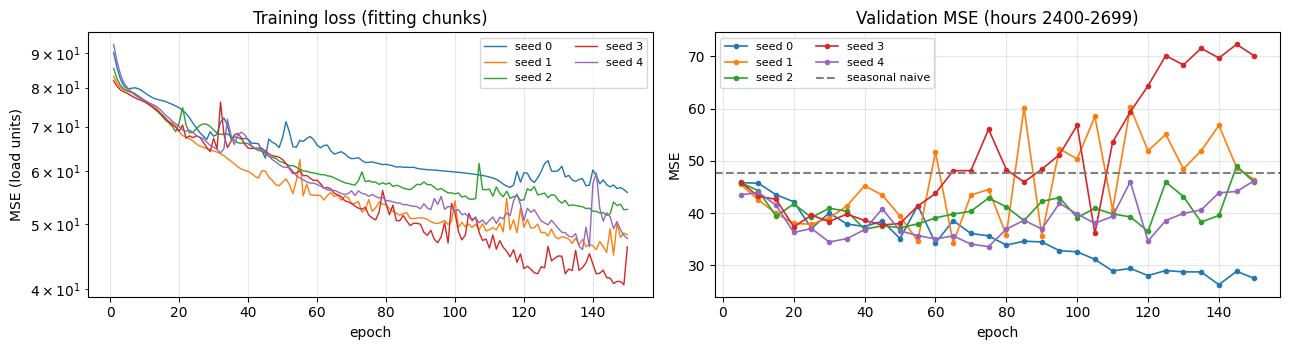

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for seed, record in enumerate(records):
    axes[0].plot(np.arange(1, 151), np.array(record["train_loss"]) * std ** 2, lw=1, label=f"seed {seed}")
    axes[1].plot(record["epoch"], record["val_mse"], lw=1.2, marker=".", label=f"seed {seed}")
axes[0].set(yscale="log", title="Training loss (fitting chunks)", xlabel="epoch", ylabel="MSE (load units)")
axes[1].axhline(mse(y_val, naive_val), color="gray", ls="--", label="seasonal naive")
print("training MSE at epoch 1:  ", np.round([r["train_loss"][0] * std ** 2 for r in records], 1))
print("training MSE at epoch 150:", np.round([r["train_loss"][-1] * std ** 2 for r in records], 1))
axes[1].set(title="Validation MSE (hours 2400-2699)", xlabel="epoch", ylabel="MSE")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

The training loss, in load units, falls slowly and with a few spikes, where an update overshoots, from between 82 and 93 at the first epoch to between 46 and 56 after 150 epochs. The validation MSE tells a different story. All five networks beat the seasonal naive forecast on the validation period (47.70) from the first check, at epoch 5, but then the curves part. Seed 0 keeps improving until epoch 140 (26.28). The validation MSE of seeds 1 and 3 starts to rise after about 60 epochs and climbs well above the seasonal naive forecast, to about 60 and 70, while their training loss keeps falling: they overfit. Early stopping picks epochs between 65 and 140, with validation MSEs between 26.28 and 36.52. The validation MSEs are much larger than the test MSEs below. The validation period is simply harder to forecast (the seasonal naive MSE is 47.70 there, against 22.29 on the test period), partly because of the drop of the load level that we saw in Chapter 17.

## Forecasts on the test period

We forecast the test period with each of the five early-stopped networks, and with their **ensemble**, the average of the five forecasts.

test MSE by seed: [19.45 15.45 17.45 20.35 16.42]
mean 17.82, range 15.45-20.35
ensemble of the 5 seeds: 14.47
seasonal naive:          22.29


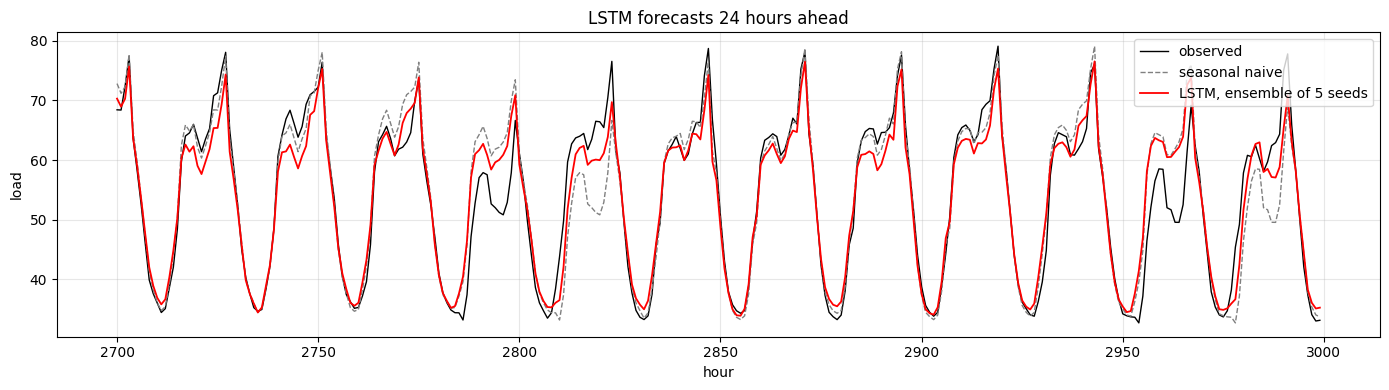

In [10]:
forecasts = np.array([lstm_forecast(net)[test] for net in nets])

seed_mse = [mse(y_test, fc) for fc in forecasts]

y_lstm = forecasts.mean(axis=0)
print("test MSE by seed:", np.round(seed_mse, 2))
print(f"mean {np.mean(seed_mse):.2f}, range {np.min(seed_mse):.2f}-{np.max(seed_mse):.2f}")
print(f"ensemble of the 5 seeds: {mse(y_test, y_lstm):.2f}")
print(f"seasonal naive:          {mse(y_test, naive_test):.2f}")

ax = run_sequence_plot(y_test, x=test_hours, color="black", figsize=(14, 4), label="observed",
                       xlabel="hour", ylabel="load", title="LSTM forecasts 24 hours ahead")
ax.plot(test_hours, naive_test, color="gray", ls="--", lw=1, label="seasonal naive")
ax.plot(test_hours, y_lstm, color="red", lw=1.3, label="LSTM, ensemble of 5 seeds")
ax.legend(); plt.tight_layout(); plt.show()

Every early-stopped network beats the seasonal naive forecast (22.29) on the test period, with MSEs from 15.45 to 20.35 (mean 17.82). Their ensemble is better than any of them, with an MSE of 14.47, 35% below the seasonal naive forecast. The errors of the five networks are partly independent, so averaging cancels part of them. Averaging a few networks trained from different seeds is a cheap and reliable way to reduce the variance of neural network forecasts.

The plot shows where the gain comes from. Like the MLP and the ESN, the LSTM misses the two low days of the test period, around hours 2790 and 2955, and forecasts an ordinary day. But on the following days, around hours 2815 and 2980, it does not repeat the low day, as the seasonal naive forecast does.

## Why forecast the change?

To see what the skip connection contributes, we repeat the training with the direct target, $y(t) \approx x(t+24)$, for the first three seeds, with everything else unchanged.

In [11]:
X_direct, Y_direct = make_chunks(x_scaled, end=n_fit, residual=False)

start = time.perf_counter()
for seed in range(3):
    net_direct, record_direct = fit_with_early_stopping(seed, X_direct, Y_direct, residual=False)
    direct_mse = mse(y_test, lstm_forecast(net_direct, residual=False)[test])
    print(f"seed {seed}: stopped at epoch {record_direct['best_epoch']:3d}, "
          f"validation MSE {min(record_direct['val_mse']):.2f}, test MSE {direct_mse:.2f}  "
          f"(change target: {seed_mse[seed]:.2f})")
print(f"3 fits in {time.perf_counter() - start:.0f} s")

seed 0: stopped at epoch 115, validation MSE 38.47, test MSE 24.15  (change target: 19.45)
seed 1: stopped at epoch 115, validation MSE 28.70, test MSE 21.45  (change target: 15.45)
seed 2: stopped at epoch  80, validation MSE 36.40, test MSE 27.72  (change target: 17.45)
3 fits in 87 s


seed 1: stopped at epoch 115, validation MSE 28.70, test MSE 21.45  (change target: 15.45)


seed 2: stopped at epoch  80, validation MSE 36.40, test MSE 27.72  (change target: 17.45)
3 fits in 60 s


With the direct target, the same three seeds reach test MSEs of 24.15, 21.45 and 27.72, against 19.45, 15.45 and 17.45 with the change target, and two of the three are worse than the seasonal naive forecast (22.29). Their best validation MSEs (28.70 to 38.47) are in the same range as with the change target (26.28 to 36.52), so the validation period alone would not have revealed the difference. The likely reason is that, with the direct target, the network first has to learn to reproduce the daily cycle, which the change target gets for free from $x(t)$, and 2,400 hours of data are not enough to learn it as precisely. Using what we already know about a series, here its seasonal naive forecast, is as useful for a neural network as for the models of the earlier chapters.

## Comparison with the earlier chapters

In [12]:
comparison = pd.DataFrame({
    "test MSE": [mse(y_test, naive_test), 18.48, 12.45, 16.17, np.mean(seed_mse), mse(y_test, y_lstm)],
    "source": ["computed above", "Chapter 16", "Chapter 16", "Chapter 17", "computed above", "computed above"]},
    index=["seasonal naive", "MLP, 48-hour window (mean of 3 seeds)", "linear, 168-hour window",
           "ESN, 900 units, ridge readout", "LSTM, 16 units (mean of 5 seeds)", "LSTM, ensemble of 5 seeds"])
comparison.round(2)

,test MSE,source
seasonal naive,22.29,computed above
"MLP, 48-hour window (mean of 3 seeds)",18.48,Chapter 16
"linear, 168-hour window",12.45,Chapter 16
"ESN, 900 units, ridge readout",16.17,Chapter 17
"LSTM, 16 units (mean of 5 seeds)",17.82,computed above
"LSTM, ensemble of 5 seeds",14.47,computed above


The LSTM ensemble (14.47) is the best of the neural networks of Chapters 16 to 18, ahead of the ESN (16.17) and the MLP (18.48). A single LSTM (mean 17.82) is about as good as the MLP and worse than the ESN, though we did not try to average several ESNs, which might help them too. The best model in the table is still the linear forecaster with a one-week window (12.45). Its window contains the load at the same hour one week before the target, the information that anticipates the low days, and the LSTM did not learn to use that information, as we see next.

Two caveats apply. The window of the linear model and the configuration of the ESN were chosen after looking at the test period, so their MSEs are optimistic. And the test period is only 12.5 days long, so differences of one or two MSE units are within the seed-to-seed spread of the LSTM (15.45 to 20.35).

## Looking inside the LSTM

The gates and the cell state are internal variables that we can look at. We run the first network over the whole series again, keep the cache, and plot its 16 forget gates and the load over the last two weeks of the series.

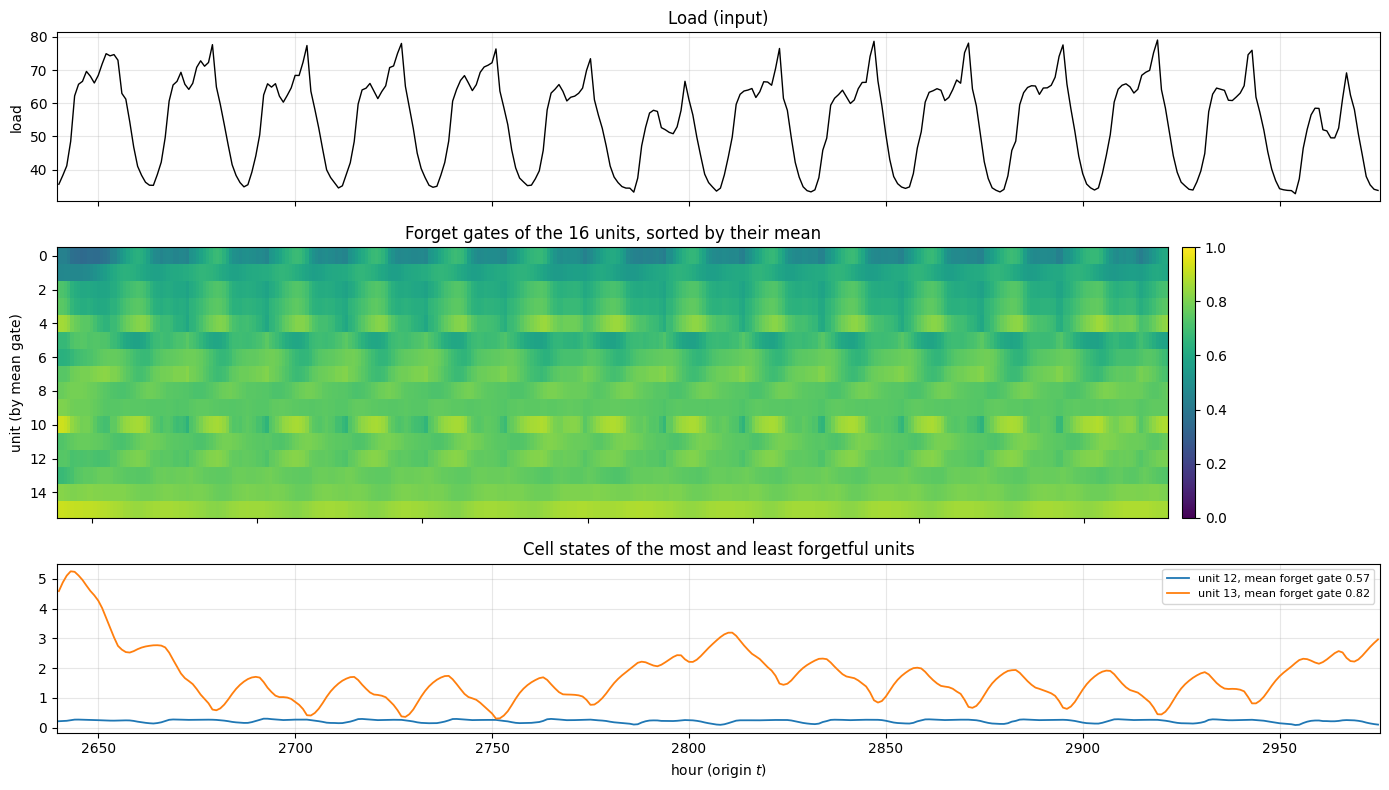

mean forget gate by unit: [0.57 0.61 0.66 0.68 0.7  0.7  0.73 0.75 0.75 0.76 0.77 0.77 0.77 0.78
 0.78 0.82]
share of the cell state kept over  24 hours, median over time, largest over the units: 1.3e-02
share of the cell state kept over 168 hours, median over time, largest over the units: 4.3e-16
restarting 168 hours before each test forecast changes it by at most 0.2425
restarting 336 hours before each test forecast changes it by at most 0.0000


restarting 168 hours before each test forecast changes it by at most 0.2425


restarting 336 hours before each test forecast changes it by at most 0.0000


In [13]:
net = nets[0]
_, cache = net.forward(x_scaled[:len(origins), None, None])
F = cache["F"][:, 0, :]                                # forget gates, (steps, units)
C = cache["C"][1:, 0, :]                               # cell states
window = np.arange(len(origins) - 336, len(origins))   # the last two weeks of origins
order = np.argsort(F.mean(axis=0))                     # units sorted by their mean forget gate

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1.6, 1]})
run_sequence_plot(time_series[window], x=window, ax=axes[0], color="black",
                  title="Load (input)", xlabel="", ylabel="load")
im = axes[1].imshow(F[window][:, order].T, aspect="auto", cmap="viridis", vmin=0, vmax=1,
                    extent=(window[0] - 0.5, window[-1] + 0.5, 15.5, -0.5))
axes[1].set(title="Forget gates of the 16 units, sorted by their mean", ylabel="unit (by mean gate)")
fig.colorbar(im, ax=axes[1], pad=0.01)
for j in order[[0, -1]]:
    axes[2].plot(window, C[window, j], lw=1.3, label=f"unit {j}, mean forget gate {F[:, j].mean():.2f}")
axes[2].set(title="Cell states of the most and least forgetful units", xlabel="hour (origin $t$)")
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("mean forget gate by unit:", np.round(np.sort(F.mean(axis=0)), 2))

log_f = np.cumsum(np.log(F), axis=0)
for lag in [24, 168]:
    kept = np.exp(log_f[lag:] - log_f[:-lag])         # product of the forget gates over `lag` hours
    print(f"share of the cell state kept over {lag:3d} hours, median over time, "
          f"largest over the units: {np.median(kept, axis=0).max():.1e}")

for L in [168, 336]:                                   # restart from h = c = 0, L hours before each forecast
    X_restart = np.stack([x_scaled[t - L + 1:t + 1] for t in origins[test]], axis=1)[..., None]
    restarted = (x_scaled[origins[test]] + net.forward(X_restart)[0][-1]) * std + mean
    print(f"restarting {L} hours before each test forecast changes it by at most "
          f"{np.max(np.abs(restarted - lstm_forecast(net)[test])):.4f}")

The forget gates are far from the values near 1 that a long memory needs. Their means range from 0.57 to 0.82 across the 16 units, and they move with the daily cycle: several units keep more of their cell state at one time of the day than at another. The share of a cell state that survives 24 hours, the product of 24 forget gates, has a median of at most 0.013 for every unit, and over a week, it is below $10^{-15}$. The cell state of the least forgetful unit follows the daily cycle and the level of the last day or so, and that of the most forgetful unit hardly moves.

The restart check confirms it from the forecasts. Restarting the LSTM from a zero state 168 hours before each test forecast changes the forecast by at most 0.24 load units, and restarting it 336 hours before does not change it at all, to four decimals. History older than one week hardly moves the forecasts, and history older than two weeks does not move them at all. (This is also why training on two-week chunks and forecasting in one pass over 3,000 hours give the same model.)

The network has the machinery for a long memory, but training did not use it. This links back to the gradient experiment: with $b_f = 1$, the sensitivity of an output to the cell state 100 steps earlier is about $10^{-7}$ at the start of training, and the lag that would anticipate a low day is 144 steps, from the forecast origin $t$ back to the same hour one week before the target. The fitting period holds only about 14 weekly cycles, a weak signal at a long lag, while the daily corrections need only a short memory, and that is what training found. Two remedies, which we leave as experiments, are to give the network the information directly, for example the load one week before the target, $x(t-144)$, as a second input (`n_inputs=2`), or a day-of-week indicator; or to train on much more data, for example on many load series at once.

## The same model in PyTorch

With a deep-learning library, we only define the forward pass. The library computes the gradients by automatic differentiation, which replaces our `backward` method, and runs the loops in compiled code, often on a GPU. The code below, not executed here, builds the same model as above in PyTorch and trains it on the same arrays `X_fit`, `Y_fit` and `mask`. Two details differ from our class. PyTorch orders the four blocks as $\mathbf{i}, \mathbf{f}, \tilde{\mathbf{c}}, \mathbf{o}$, and it has two bias vectors, whose sum is our $\mathbf{b}$, so we set the forget-gate bias by hand.

```python
import torch
from torch import nn


class LSTMForecaster(nn.Module):
    def __init__(self, n_inputs=1, n_units=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_inputs, hidden_size=n_units)   # time-major, like our class
        self.readout = nn.Linear(n_units, 1)
        with torch.no_grad():                                           # forget-gate bias 1
            self.lstm.bias_ih_l0[n_units:2 * n_units].fill_(1.0)
            self.lstm.bias_hh_l0[n_units:2 * n_units].fill_(0.0)

    def forward(self, x):                        # x: (T, B, n_inputs)
        h, _ = self.lstm(x)                      # hidden states of every step, (T, B, n_units)
        return self.readout(h).squeeze(-1)       # outputs y(t), (T, B)


model = LSTMForecaster()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
X_t, Y_t, mask_t = (torch.tensor(a, dtype=torch.float32) for a in (X_fit, Y_fit, mask))
for epoch in range(150):
    optimizer.zero_grad()
    loss = (((model(X_t) - Y_t) * mask_t) ** 2).sum() / mask_t.sum()
    loss.backward()                              # backpropagation through time, automatically
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
```

In Keras, the layer is `keras.layers.LSTM(16, return_sequences=True)`, which sets the forget-gate bias to 1 by default. Stacking LSTM layers, switching to `nn.GRU`, or training on a GPU is a change of one or two lines.

---

# Summary

**LSTM unit**: a cell state $\mathbf{c}(t)$ that changes only through element-wise operations, controlled by three gates, each a sigmoid layer of $[\mathbf{h}(t-1), x(t)]$:

$$\mathbf{c}(t) = \mathbf{f}(t) \odot \mathbf{c}(t-1) + \mathbf{i}(t) \odot \tilde{\mathbf{c}}(t), \qquad \mathbf{h}(t) = \mathbf{o}(t) \odot \tanh\big(\mathbf{c}(t)\big).$$

- **Gates.** The forget gate $\mathbf{f}(t)$ erases, the input gate $\mathbf{i}(t)$ writes the candidate $\tilde{\mathbf{c}}(t)$, and the output gate $\mathbf{o}(t)$ decides what the cell reveals in $\mathbf{h}(t)$. An LSTM layer has $4 N_h (N_h + d + 1)$ parameters, four times an RNN layer. A hand-wired unit can write a value, hold it for 60 steps and erase it in one; an RNN unit cannot.
- **Gradient flow.** Along the cell state, $\partial \mathbf{c}(t) / \partial \mathbf{c}(t-1) = \mathrm{diag}\big(\mathbf{f}(t)\big)$, with no weight matrix and no squashing derivative. With forget gates near 1, the gradient reaches 100 steps back undiminished; with a forget-gate bias of 0, it vanishes as in an RNN ($5.8 \times 10^{-20}$ after 100 steps). Initialize the forget-gate bias to 1 or more. Check hand-written gradients against finite differences.
- **Variants.** Peephole connections, coupled forget and input gates, and the GRU (update and reset gates, three layers, 25% fewer parameters). Large comparisons found no variant consistently better than the standard LSTM; the LSTM and the GRU are the default choices. A bidirectional LSTM reads the future, so it cannot forecast.
- **Training for forecasting.** Cut the series into overlapping chunks (truncated backpropagation through time), leave a washout out of the loss, train with Adam and gradient clipping, stop early on a validation period, and average several seeds. Forecasting the change from the seasonal naive forecast (a skip connection) worked much better than forecasting the load directly.